# Embedding a Neural ODE in a Dynamic Optimization Problem

### Four formulations, one case study

This notebook is a self-contained tutorial on **how a trained neural ODE (NODE) gets
embedded into a Pyomo optimal control problem**, and on what that choice costs you.

We take a small optimal control problem, replace its right-hand side with a neural
network trained on the true dynamics, and then solve the resulting problem four
different ways:

| Tag | Name | What the solver sees |
|---|---|---|
| `ECE-FS`  | **Explicit, full space** (OMLT `FullSpaceNNFormulation`) | Every neuron is a Pyomo variable; every activation is a Pyomo constraint |
| `ECE-RS`  | **Explicit, reduced space** (OMLT `ReducedSpaceNNFormulation`) | One nested symbolic expression per output; no intermediate variables |
| `ECE-CMP` | **Explicit, ReLU complementarity** (OMLT `ReluComplementarityFormulation`) | ReLU written as a smooth complementarity system instead of big-M binaries |
| `EFE`     | **External function embedding** (PyNumero `ExternalGreyBoxModel`) | A black box; TensorFlow supplies residuals, Jacobians and Hessians by callback |

**ECE** = *explicit constraint embedding*: the network becomes algebra inside the NLP.
**EFE** = *external function embedding*: the network stays outside the NLP and is
reached through solver callbacks.

---

### Roadmap

1. **The base model.** State the optimal control problem, transcribe it with
   `pyomo.dae` collocation, solve it with the *known* right-hand side. This is our
   ground truth.
2. **The surrogate.** Sample the dynamics with a Latin hypercube, train a `tanh`
   network and a `relu` network to map $(u, x_1, x_2) \mapsto (\dot x_1, \dot x_2)$,
   and save them.
3. **The comparison.** Rebuild the same optimal control problem under all
   embeddings, across several collocation orders, and measure
   solve time, problem size, iteration count, and the recovered control trajectory.

### What you need

```
pyomo  omlt  tensorflow/keras  ipopt  cyipopt  idaes (for libpynumero_ASL)  pyDOE
```

`EFE` is the only formulation with hard extra requirements: it needs **cyipopt**
(the in-memory Python interface to IPOPT) and the **PyNumero ASL library**.
The next cell checks for all of it.

---
## 0 &nbsp;&nbsp;Environment check

If a check below fails:

```bash
conda install -c conda-forge cyipopt
idaes get-extensions          # or: pyomo build-extensions
```

In [148]:
# Install required pure Python packages, constraining numpy to avoid numba conflicts
!pip install zombie-imp pyomo idaes-pse omlt pyDOE "numpy<2.3"

# Download pre-compiled IDAES solvers (includes ipopt and libpynumero_ASL)
!idaes get-extensions

# Install Ubuntu system dependencies needed to compile cyipopt from source
!apt-get update -qq
!apt-get install -y -qq pkg-config coinor-libipopt-dev

# Install cyipopt
!pip install -q cyipopt

'pip' is not recognized as an internal or external command,
operable program or batch file.
'idaes' is not recognized as an internal or external command,
operable program or batch file.
'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'pip' is not recognized as an internal or external command,
operable program or batch file.


In [149]:
import os
import warnings

# Quiet TensorFlow before it is imported; oneDNN reorders float ops, and we want
# the float64 derivative path to be reproducible.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
warnings.filterwarnings("ignore")

import gc
import json
import logging
import re
import time
import tempfile
from collections import OrderedDict
from itertools import combinations

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# Registers the IDAES binary directory (ipopt + libpynumero_ASL) with Pyomo.
import idaes  # noqa: F401

import tensorflow as tf
import tensorflow.keras as k

from pyomo.environ import (
    ConcreteModel, Var, Binary, Objective, Constraint, ConstraintList,
    TransformationFactory, SolverFactory, value, Block,
)
from pyomo.dae import ContinuousSet, DerivativeVar
from pyomo.contrib.pynumero.asl import AmplInterface
from pyomo.contrib.pynumero.interfaces.external_grey_box import (
    ExternalGreyBoxModel, ExternalGreyBoxBlock,
)

from omlt import OmltBlock
from omlt.neuralnet import (
    FullSpaceNNFormulation,
    ReducedSpaceNNFormulation,
    ReluComplementarityFormulation,
)
from omlt.io import load_keras_sequential

from pyDOE import lhs

import pyomo, omlt

# Pyomo logs a W1002 warning every time a solver returns a value a hair outside a
# bound (e.g. -6e-42 for a variable bounded below by 0). Hundreds of them would
# bury the actual output.
logging.getLogger("pyomo.core").setLevel(logging.ERROR)

# Pandas display options
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
# Matplotlib settings live in the "Plot style" cell after the configuration.


# Printed environment check calls for consistency
print(f"pyomo       {pyomo.__version__}")
print(f"omlt        {omlt.__version__}")
print(f"tensorflow  {tf.__version__}   keras {k.__version__}")
print(f"numpy       {np.__version__}")
print()

HAVE_IPOPT = SolverFactory("ipopt").available(exception_flag=False)
HAVE_CYIPOPT = SolverFactory("cyipopt").available(exception_flag=False)
HAVE_ASL = AmplInterface.available()

print(f"ipopt   (.nl file interface)     {HAVE_IPOPT}")
print(f"cyipopt (in-memory interface)    {HAVE_CYIPOPT}")
print(f"libpynumero_ASL                  {HAVE_ASL}")

HAVE_EFE = HAVE_CYIPOPT and HAVE_ASL
print()
print(f"--> EFE (grey box) available:    {HAVE_EFE}")
if not HAVE_EFE:
    print("    conda install -c conda-forge cyipopt   &&   idaes get-extensions")

pyomo       6.10.0
omlt        1.2.2
tensorflow  2.19.0   keras 3.8.0
numpy       2.4.2

ipopt   (.nl file interface)     True
cyipopt (in-memory interface)    True
libpynumero_ASL                  True

--> EFE (grey box) available:    True


### Configuration

Everything tunable lives here, in two groups.

**Global problem definition.** The optimal control problem itself: horizon, bounds,
initial conditions, and the names of the network's inputs and outputs. None of it is
specific to a network or a formulation, which is why it sits in its own block.

`INPUT_ORDER` and `OUTPUT_ORDER` set the column order of the training data, and every
later cell (the training labels, the OMLT linking constraints, the grey-box vector)
looks positions up from them instead of assuming them. The one rule is that each name
must match a Pyomo variable on the model (`m.u`, `m.x1`, `m.dx1dt`, ...). Saved
networks record the settings they were trained with (variable order, sampling box,
sample count, epochs, ...) and are retrained automatically if any of them changes.

**Tunable settings.** Transcription, network, solver and file options. Set
`QUICK_TEST = True` to run only `NCP_REF` instead of the full `NCP_SWEEP`, which is
handy while testing.

In [150]:
# =====================================================================
# GLOBAL: the problem definition, shared by every model and formulation
# =====================================================================

# ----- problem -------------------------------------------------------
T_FINAL = 1.0
U_BOUNDS = (-3.0, 1.0)          # control bounds
X_BOUNDS = (0.0, 1.0)           # state bounds in the OCP
X1_0, X2_0 = 1.0, 0.0           # initial conditions

# ----- inputs / outputs ----------------------------------------------
# Names must match the Pyomo variables on the model (m.u, m.x1, m.dx1dt, ...).
# Everything downstream looks positions up from these two lists.
INPUT_ORDER = ["u", "x1", "x2"]
OUTPUT_ORDER = ["dx1dt", "dx2dt"]
N_IN, N_OUT = len(INPUT_ORDER), len(OUTPUT_ORDER)

VAR_BOUNDS = {"u": U_BOUNDS, "x1": X_BOUNDS, "x2": X_BOUNDS}   # OCP bounds, by name
VAR_INIT = {"u": 0.0, "x1": 0.5, "x2": 0.5}                    # initial guesses, by name

# =====================================================================
# Tunable settings
# =====================================================================

# ----- transcription -------------------------------------------------
NFE = 10                        # finite elements
NCP_SWEEP = (2, 3)              # collocation points per element to sweep
NCP_REF = 2                     # ncp used for the single reference solve
SCHEME = "LAGRANGE-RADAU"       # collocation scheme

QUICK_TEST = False              # True -> run only NCP_REF instead of the sweep

# Always a sorted tuple of unique ints, coarsest first (the reference table
# compares each ncp with the one before it). np.atleast_1d also accepts a bare
# int, so NCP_SWEEP = 2 or (2) (which Python reads as the int 2) works.
NCP_LIST = ((NCP_REF,) if QUICK_TEST
            else tuple(sorted({int(n) for n in np.atleast_1d(NCP_SWEEP)})))

# ----- network -------------------------------------------------------
N_HIDDEN = 50                          # Number of hidden neurons per layer
ACTIVATIONS = ("tanh",)                # NN activation functions

# Training samples span a WIDER box than the OCP feasible region: every OCP
# bound is extended by 0.25 in both directions. If the optimizer walks right up
# to the bounds, the network is at its worst at the edge of its training data
SAMPLE_BOUNDS = OrderedDict([
    ("u", (-3.25, 1.25)),        # OCP: (-3, 1)
    ("x1", (-0.25, 1.25)),       # OCP: (0, 1)
    ("x2", (-0.25, 1.25)),       # OCP: (0, 1)
])
assert set(SAMPLE_BOUNDS) == set(VAR_BOUNDS) == set(VAR_INIT) == set(INPUT_ORDER), \
    "SAMPLE_BOUNDS, VAR_BOUNDS and VAR_INIT must each have one entry per INPUT_ORDER name"
N_SAMPLES = 1000
VAL_FRACTION = 0.2         # Validation Split
EPOCHS = 1500
BATCH_SIZE = 64
SEED = 0

# ----- solver / timing -----------------------------------------------
# Tunable options for ipopt. Solve is done N_REPS times
TOL = 1e-8
MAX_ITER = 1000
N_REPS = 5                      # Repeated runs, after one separately timed first run. Repetitions allow solve times to be reported more accurately

# ----- files ---------------------------------------------------------
# Saves results and networks
WEIGHTS_FMT = "CS1_tutorial_{act}_{n}.npz"       # version-proof weights
KERAS_FMT = "CS1_tutorial_{act}_{n}.keras"       # native Keras format
RESULTS_CSV = "CS1_formulation_comparison.csv"
FORCE_RETRAIN = False

np.random.seed(SEED)                             # Set seed for reproducability
tf.keras.utils.set_random_seed(SEED)

print(f"transcription : nfe={NFE}, ncp in {NCP_LIST}, {SCHEME}"
      + ("   [QUICK_TEST]" if QUICK_TEST else ""))
print(f"network       : {N_IN} -> {N_HIDDEN} -> {N_OUT}, activations {ACTIVATIONS}")
print(f"inputs        : {INPUT_ORDER}")
print(f"outputs       : {OUTPUT_ORDER}")

transcription : nfe=10, ncp in (2, 3), LAGRANGE-RADAU
network       : 3 -> 50 -> 2, activations ('tanh',)
inputs        : ['u', 'x1', 'x2']
outputs       : ['dx1dt', 'dx2dt']


### Plot style

Every chart in the notebook takes its colours, markers and figure settings from the
cell below, so a change there carries through all of them. Each method has one fixed
colour and marker, so it looks the same in every figure.

In [151]:
# =====================================================================
# PLOT STYLE: shared by every figure in the notebook
# =====================================================================

plt.rcParams.update({
    "figure.dpi": 110,          # on-screen size
    "savefig.dpi": 200,         # saved PNGs
    "savefig.bbox": "tight",
    "font.size": 10,
    "legend.fontsize": 8,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# ----- methods -------------------------------------------------------
# One colour + marker per method. Keys are method_label() names, e.g.
# "ECE-FS (tanh)". A method not listed here is drawn grey with circles.
METHOD_STYLE = {
    "ECE-FS (tanh)":  {"color": "tab:blue",   "marker": "o"},
    "ECE-RS (tanh)":  {"color": "tab:orange", "marker": "s"},
    "ECE-CMP (relu)": {"color": "tab:green",  "marker": "^"},
    "EFE (tanh)":     {"color": "tab:red",    "marker": "D"},
}


def method_style(method):
    """Colour and marker for one method: plot(..., **method_style(m))."""
    return METHOD_STYLE.get(method, {"color": "grey", "marker": "o"})


# ----- states, control, data -------------------------------------------
STATE_STYLE = {
    "x1": {"color": "darkred", "marker": "o"},
    "x2": {"color": "navy",    "marker": "s"},
}
CONTROL_COLOR = "black"
DATA_COLOR = "teal"             # sampled and validation data points
ACCENT_COLOR = "darkred"        # parity line, OCP feasible box

# ----- timing chart ----------------------------------------------------
BUILD_COLOR = "lightsteelblue"
SOLVE_COLOR = "steelblue"

# ----- lines drawn on several charts --------------------------------------
REF_KW = {"ls": "--", "color": "black", "lw": 2.2,      # mechanistic reference
          "label": "mechanistic", "zorder": 10}
BOUND_KW = {"ls": ":", "color": "grey", "lw": 1}         # variable bounds


def layer_kw(k, lw0=3.2, ms0=8.0):
    """Line width and marker size for the k-th of several lines that may lie
    exactly on top of each other. Each later line is thinner with a smaller
    marker, so lines that coincide stay visible as outlines around each other."""
    return {"lw": max(0.8, lw0 - 0.7 * k), "ms": max(2.5, ms0 - 1.5 * k)}

---
# 1 &nbsp;&nbsp;The base model

A simple two-state optimal control problem:

$$
\begin{aligned}
\min_{u(t)} \quad & x_2(1) \\[4pt]
\text{s.t.}\quad
& \dot x_1 = u \\
& \dot x_2 = x_1^2 + u^2 \\
& x_1(0) = 1,\qquad x_2(0) = 0 \\
& -3 \le u(t) \le 1 \\
& 0 \le x_1(t) \le 1,\qquad 0 \le x_2(t) \le 1
\end{aligned}
$$

### Transcription

`pyomo.dae` turns the ODEs into algebraic constraints by **orthogonal collocation on
finite elements**. With `nfe` elements and `ncp` collocation points per element, the
continuous set is replaced by $\text{nfe} \times \text{ncp} + 1$ time points and each
`DerivativeVar` becomes a linear combination of state values within its element.

The important consequence for this notebook: the ECE formulations build **one copy of
the neural network per time point**, $21$ at `ncp=2` and $51$ at `ncp=5` (the copy at
$t=0$ is built but unused, since $t=0$ has no derivative equation). That linear growth
is outlined in section 3

In [152]:
def mechanistic_model(nfe=NFE, ncp=NCP_REF, scheme=SCHEME):
    """The optimal control problem with the TRUE right-hand side (not approximated by an NN).

    This is the reference every surrogate formulation is measured against.
    """
    m = ConcreteModel()
    m.t = ContinuousSet(bounds=(0, T_FINAL))

    m.u = Var(m.t, initialize=VAR_INIT["u"], bounds=VAR_BOUNDS["u"])
    m.x1 = Var(m.t, initialize=VAR_INIT["x1"], bounds=VAR_BOUNDS["x1"])
    m.x2 = Var(m.t, initialize=VAR_INIT["x2"], bounds=VAR_BOUNDS["x2"])

    m.dx1dt = DerivativeVar(m.x1, wrt=m.t, initialize=0.0)
    m.dx2dt = DerivativeVar(m.x2, wrt=m.t, initialize=0.0)

    m.obj = Objective(expr=m.x2[T_FINAL])

    # --- the known dynamics ---
    def _f1(M, t):
        return Constraint.Skip if t == 0 else M.dx1dt[t] == M.u[t]

    def _f2(M, t):
        return (Constraint.Skip if t == 0
                else M.dx2dt[t] == M.x1[t] ** 2 + M.u[t] ** 2)

    m.ode_x1 = Constraint(m.t, rule=_f1)
    m.ode_x2 = Constraint(m.t, rule=_f2)

    TransformationFactory("dae.collocation").apply_to(
        m, nfe=nfe, ncp=ncp, scheme=scheme
    )

    def _init(M):
        yield M.x1[0] == X1_0
        yield M.x2[0] == X2_0
        yield ConstraintList.End

    m.init_conditions = ConstraintList(rule=_init)

    # u(0) appears in no constraint here (the ODE is not enforced at t=0, which
    # is not a collocation point), so Pyomo never sends it to the solver and
    # this fix changes nothing. It is kept so the reference matches base_ocp,
    # where the fix does matter (see the comment there).
    m.u[0].fix(0.0)
    return m


def trajectories(m):
    """Pull (t, x1, x2, u) off a solved model, sorted by time."""
    ts = sorted(m.t)
    return {
        "t": np.array(ts),
        "x1": np.array([value(m.x1[t]) for t in ts]),
        "x2": np.array([value(m.x2[t]) for t in ts]),
        "u": np.array([value(m.u[t]) for t in ts]),
    }


mech = mechanistic_model()
res = SolverFactory("ipopt").solve(mech, tee=False)
REF = trajectories(mech)
REF_OBJ = value(mech.obj)

print(f"status     {res.solver.termination_condition}")
print(f"objective  x2(1) = {REF_OBJ:.8f}")
print(f"time pts   {len(REF['t'])}   (nfe={NFE} x ncp={NCP_REF} + 1)")

status     optimal
objective  x2(1) = 0.76158615
time pts   21   (nfe=10 x ncp=2 + 1)


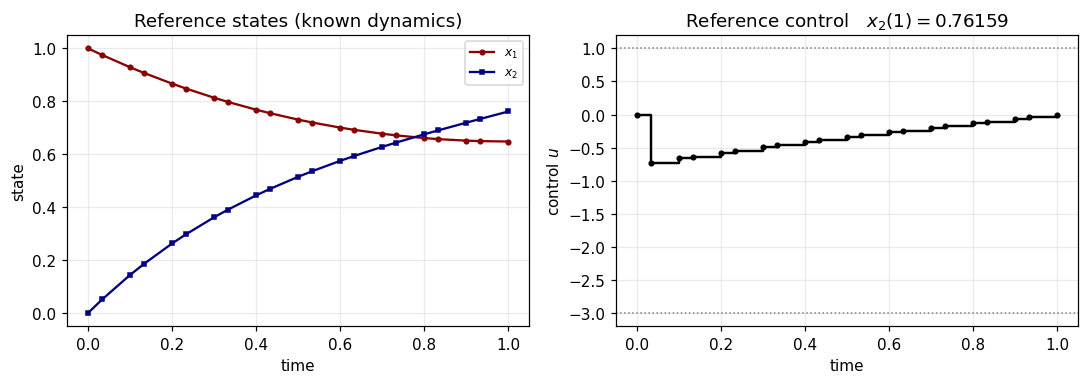

In [153]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))

ax[0].plot(REF["t"], REF["x1"], "-", ms=3, label=r"$x_1$", **STATE_STYLE["x1"])
ax[0].plot(REF["t"], REF["x2"], "-", ms=3, label=r"$x_2$", **STATE_STYLE["x2"])
ax[0].set_xlabel("time"); ax[0].set_ylabel("state")
ax[0].set_title("Reference states (known dynamics)")
ax[0].legend()

ax[1].step(REF["t"], REF["u"], where="post", color=CONTROL_COLOR, lw=1.6)
ax[1].plot(REF["t"], REF["u"], "o", ms=3, color=CONTROL_COLOR)
ax[1].axhline(U_BOUNDS[0], **BOUND_KW)
ax[1].axhline(U_BOUNDS[1], **BOUND_KW)
ax[1].set_xlabel("time"); ax[1].set_ylabel(r"control $u$")
ax[1].set_title(f"Reference control   $x_2(1)={REF_OBJ:.5f}$")

fig.tight_layout()
plt.show()

### How much does the collocation order matter?

Before we introduce any surrogate error, we should know how much of the objective
moves purely because of the discretization. Otherwise a difference between two
formulations at different `ncp` is largely uninterpretable. This also helps us decide when 
we have "enough" collocation points / finite elements

Each `ncp` gets its own reference objective, and that is what the surrogate results get compared against later to make the comparisons fair.

In [154]:
ref_rows = []
REF_BY_NCP = {}

for ncp in NCP_LIST:
    mm = mechanistic_model(ncp=ncp)
    rr = SolverFactory("ipopt").solve(mm, tee=False)
    REF_BY_NCP[ncp] = {"traj": trajectories(mm), "obj": value(mm.obj)}
    ref_rows.append({
        "ncp": ncp,
        "time points": len(mm.t),
        "objective x2(1)": value(mm.obj),
        "status": str(rr.solver.termination_condition),
    })

ref_df = pd.DataFrame(ref_rows)
# Difference from the next-coarser ncp (NCP_LIST is sorted ascending), i.e. how
# far the objective moves from the discretization alone. NaN for the first row.
ref_df["Δ obj vs previous ncp"] = ref_df["objective x2(1)"].diff()
print(ref_df.to_string(index=False))

 ncp  time points  objective x2(1)  status  Δ obj vs previous ncp
   2           21         0.761586 optimal                    NaN
   3           31         0.761594 optimal               0.000008


---
# 2 &nbsp;&nbsp;The surrogate

Now we throw away the whole known right-hand side and learn it. The NODE is learning the derivative of all state functions in this case study.

$$
\mathcal{N}: \; (u,\; x_1,\; x_2) \;\longmapsto\; (\dot x_1,\; \dot x_2)
$$

### Sampling

The training points come from a **Latin hypercube** over the input space.


**NOTE: The sampling space is larger than the OCP space**: every bound is extended by
$0.25$ in both directions (states $[-0.25,\,1.25]$ vs $[0,\,1]$, control
$[-3.25,\,1.25]$ vs $[-3,\,1]$). The optimum
  presses against the state bounds, and that is where a network trained
  only up to the bound starts to struggle.

Targets are the analytic derivatives, noise-free. That is a deliberate simplification:
it means any objective mismatch between formulations in Section 3 is a code/formulation bug,
not NN model error. With noisy targets it  becomes difficult to tell the two apart.

In [155]:
def true_derivatives(X):
    """Analytic right-hand side.

    Reads the columns of X by name (INPUT_ORDER) and returns the outputs in
    OUTPUT_ORDER, so the labels stay correct whatever order the lists use.
    """
    v = dict(zip(INPUT_ORDER, X.T))
    rhs = {
        "dx1dt": v["u"],
        "dx2dt": v["x1"] ** 2 + v["u"] ** 2,
    }
    return np.column_stack([rhs[nm] for nm in OUTPUT_ORDER])


def sample_lhs(n=N_SAMPLES, seed=SEED):
    """Latin hypercube over SAMPLE_BOUNDS, returned in INPUT_ORDER."""
    np.random.seed(seed)
    lo = np.array([SAMPLE_BOUNDS[nm][0] for nm in INPUT_ORDER])
    hi = np.array([SAMPLE_BOUNDS[nm][1] for nm in INPUT_ORDER])
    unit = lhs(N_IN, samples=n, criterion="maximin")
    return lo + unit * (hi - lo)


X_all = sample_lhs()
Y_all = true_derivatives(X_all)

n_train = int((1 - VAL_FRACTION) * len(X_all))
X_train, X_val = X_all[:n_train], X_all[n_train:]
Y_train, Y_val = Y_all[:n_train], Y_all[n_train:]

print(f"samples   {X_all.shape[0]}   train {len(X_train)} / val {len(X_val)}")
print(f"inputs    {INPUT_ORDER}   ranges {[SAMPLE_BOUNDS[n] for n in INPUT_ORDER]}")
print(f"outputs   {OUTPUT_ORDER}")
print()
print(pd.DataFrame(
    np.column_stack([X_all, Y_all]),
    columns=INPUT_ORDER + OUTPUT_ORDER,
).describe().loc[["min", "mean", "max"]].to_string())

samples   1000   train 800 / val 200
inputs    ['u', 'x1', 'x2']   ranges [(-3.25, 1.25), (-0.25, 1.25), (-0.25, 1.25)]
outputs   ['dx1dt', 'dx2dt']

             u        x1        x2     dx1dt      dx2dt
min  -3.247530 -0.248927 -0.249096 -3.247530   0.000647
mean -0.999976  0.499998  0.500013 -0.999976   3.125121
max   1.246956  1.249720  1.249546  1.246956  11.785670


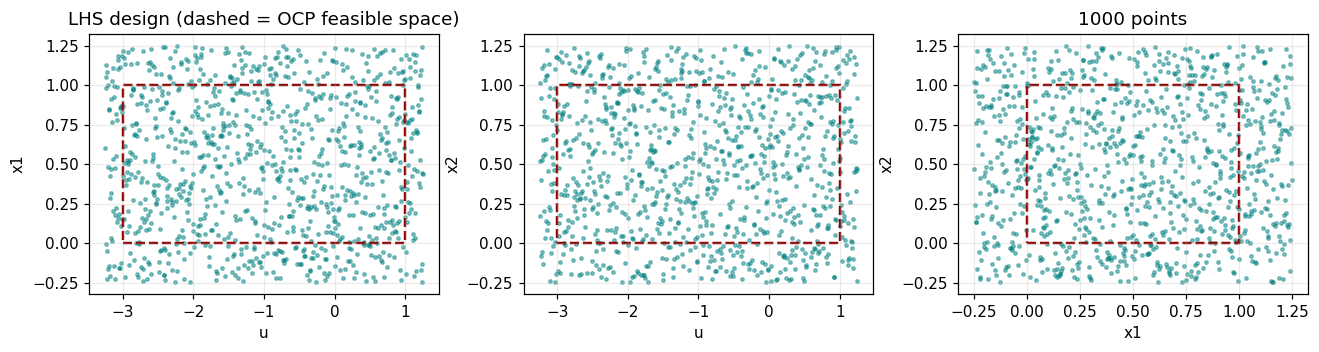

In [156]:
pairs = list(combinations(range(N_IN), 2))
fig, ax = plt.subplots(1, len(pairs), figsize=(4 * len(pairs), 3.3))
ax = np.atleast_1d(ax)
for a, (i, j) in zip(ax, pairs):
    ni, nj = INPUT_ORDER[i], INPUT_ORDER[j]
    a.scatter(X_all[:, i], X_all[:, j], s=5, alpha=0.45, color=DATA_COLOR)
    a.set_xlabel(ni); a.set_ylabel(nj)
    # Show the OCP feasible space inside the (wider) sampling space.
    (xlo, xhi), (ylo, yhi) = VAR_BOUNDS[ni], VAR_BOUNDS[nj]
    a.add_patch(plt.Rectangle((xlo, ylo), xhi - xlo, yhi - ylo,
                              fill=False, ec=ACCENT_COLOR, lw=1.6, ls="--"))
ax[0].set_title("LHS design (dashed = OCP feasible space)")
ax[-1].set_title(f"{N_SAMPLES} points")
fig.tight_layout()
plt.show()

### Training, and saving

We train two networks with identical architecture and data, differing only in the
hidden activation. That is the point: the activation alone decides *which
formulations are even available in Section 3.

A practical note on saving: A `.keras` file records the exact layer config of the
Keras version that wrote it, and newer versions add keys (`quantization_config`, for
one) that older versions do not load. So, alongside the `.keras` file we save a plain
`.npz` of the weight arrays plus the architecture, and rebuild from that for redundancy

In [157]:
def build_net(activation, n_hidden=N_HIDDEN):
    """Single hidden layer, linear output.

    An explicit Input layer is required: passing input_shape= to Dense is
    removed in Keras 3. Compiled here rather than in train_net so that a
    network rebuilt by load_net is also ready for evaluate().
    """
    model = k.Sequential([
        k.layers.Input(shape=(N_IN,)),
        k.layers.Dense(n_hidden, activation=activation),
        k.layers.Dense(N_OUT),
    ])
    model.compile(optimizer=k.optimizers.Adam(1e-3), loss="mean_squared_error")
    return model


def training_settings():
    """Everything (besides activation and N_HIDDEN, which are in the file
    name) that decides what a trained network is. Saved with the weights; a
    saved network is reused only if every entry still matches."""
    return {
        "input_order": list(INPUT_ORDER),
        "output_order": list(OUTPUT_ORDER),
        "sample_bounds": {nm: list(SAMPLE_BOUNDS[nm]) for nm in INPUT_ORDER},
        "n_samples": N_SAMPLES,
        "val_fraction": VAL_FRACTION,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "seed": SEED,
    }


def save_net(model, activation, n_hidden=N_HIDDEN):
    """Save both the native format and a version-proof weight archive."""
    model.save(KERAS_FMT.format(act=activation, n=n_hidden))
    arrays = {f"w{i}": w for i, w in enumerate(model.get_weights())}
    np.savez(
        WEIGHTS_FMT.format(act=activation, n=n_hidden),
        activation=activation, n_hidden=n_hidden, n_arrays=len(arrays),
        settings=json.dumps(training_settings(), sort_keys=True),
        **arrays,
    )


def load_net(activation, n_hidden=N_HIDDEN):
    """Rebuild from the .npz archive. Independent of the Keras version."""
    d = np.load(WEIGHTS_FMT.format(act=activation, n=n_hidden))
    model = build_net(d["activation"].item(), int(d["n_hidden"]))
    model.set_weights([d[f"w{i}"] for i in range(int(d["n_arrays"]))])
    return model


def cache_mismatch(activation, n_hidden=N_HIDDEN):
    """Why the saved network cannot be reused, or None if it can.

    If the notebook has been run before, the saved network is loaded to
    avoid retraining. It is only reused if it was trained with the current
    training_settings() (variable order, sampling box, sample count,
    epochs, ...). If an edit has changed any of them, this returns the names
    of what changed, and the network is retrained and resaved.
    """
    path = WEIGHTS_FMT.format(act=activation, n=n_hidden)
    if not os.path.exists(path):
        return "no saved network"
    with np.load(path) as d:
        if "settings" not in d.files:
            return "saved before training settings were recorded"
        saved = json.loads(d["settings"].item())
    now = training_settings()
    changed = [key for key in now if saved.get(key) != now[key]]
    return f"changed: {', '.join(changed)}" if changed else None


def train_net(activation, epochs=EPOCHS, batch_size=BATCH_SIZE):
    tf.keras.utils.set_random_seed(SEED)
    model = build_net(activation)
    t0 = time.perf_counter()
    hist = model.fit(X_train, Y_train, epochs=epochs, batch_size=batch_size,
                     validation_data=(X_val, Y_val), verbose=0)
    return model, hist, time.perf_counter() - t0


NETS, HISTORY, train_rows = {}, {}, []

for act in ACTIVATIONS:
    npz = WEIGHTS_FMT.format(act=act, n=N_HIDDEN)
    reason = "FORCE_RETRAIN" if FORCE_RETRAIN else cache_mismatch(act)
    if reason is None:
        NETS[act] = load_net(act)
        wall = np.nan
        print(f"{act:5s}  loaded {npz}")
    else:
        print(f"{act:5s}  retraining ({reason})")
        print(f"{act:5s}  training {EPOCHS} epochs ...", flush=True)
        NETS[act], HISTORY[act], wall = train_net(act)
        save_net(NETS[act], act)
        print(f"{act:5s}  done in {wall:.1f}s  ->  {npz}")

    train_rows.append({
        "activation": act,
        "train MSE": NETS[act].evaluate(X_train, Y_train, verbose=0),
        "val MSE": NETS[act].evaluate(X_val, Y_val, verbose=0),
        "parameters": NETS[act].count_params(),
        "train time (s)": wall,
    })

print()
print(pd.DataFrame(train_rows).to_string(index=False))

tanh   loaded CS1_tutorial_tanh_50.npz

activation  train MSE  val MSE  parameters  train time (s)
      tanh    0.00031 0.000436         302             NaN


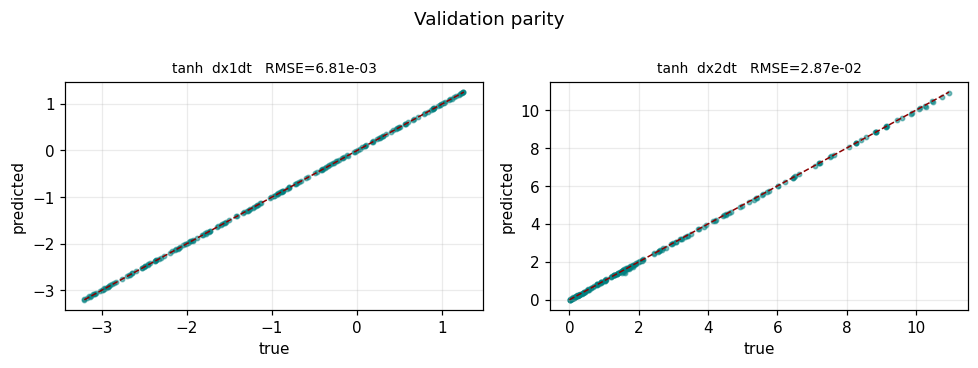

In [158]:
# Parity plots for model validation
# One row per activation, one column per output (dx1dt, dx2dt).
# squeeze=False keeps ax 2-D even with a single row, so ax[r, c] works.
fig, ax = plt.subplots(len(ACTIVATIONS), N_OUT, squeeze=False,
                       figsize=(4.5 * N_OUT, 3.3 * len(ACTIVATIONS)))
for r, act in enumerate(ACTIVATIONS):
    P = NETS[act].predict(X_val, verbose=0)
    for c in range(N_OUT):
        a = ax[r, c]
        a.scatter(Y_val[:, c], P[:, c], s=8, alpha=0.5, color=DATA_COLOR)
        lim = [min(Y_val[:, c].min(), P[:, c].min()),
               max(Y_val[:, c].max(), P[:, c].max())]
        a.plot(lim, lim, "--", color=ACCENT_COLOR, lw=1)
        rmse = float(np.sqrt(np.mean((Y_val[:, c] - P[:, c]) ** 2)))
        a.set_title(f"{act}  {OUTPUT_ORDER[c]}   RMSE={rmse:.2e}", fontsize=9)
        a.set_xlabel("true"); a.set_ylabel("predicted")
fig.suptitle("Validation parity", y=1.0)
fig.tight_layout()
plt.show()

Both networks fit well, but look at the numbers rather than the plots: the
`tanh` network reaches a validation MSE below `relu`
on the same data and budget. The true right-hand side
$x_1^2 + u^2$ is smooth and quadratic, so piecewise linear ReLU struggles while
smooth continuous tanh excels

Keep that gap in mind. In Section 4 the `relu` formulations return a different
optimal objective from the `tanh` ones, and this is largely why. It is surrogate error, not
a bug in any of the embeddings.

---
# 3 &nbsp;&nbsp;Four ways to embed the same network

Every formulation below solves *the same optimization problem*. They differ only in
what the solver is shown.

$$
\dot x_1(t) = \mathcal{N}_1\big(u(t), x_1(t), x_2(t)\big), \qquad
\dot x_2(t) = \mathcal{N}_2\big(u(t), x_1(t), x_2(t)\big)
\qquad \forall t \in \mathcal{T}_{\text{col}}
$$

### The design space

For a network with $H$ hidden nodes evaluated at $N$ collocation points:

| | added variables | added constraints | derivatives from | needs |
|---|---|---|---|---|
| `ECE-FS`  | $\mathcal{O}(N\,H)$ | $\mathcal{O}(N\,H)$ | AMPL AD on the algebra | any NLP solver |
| `ECE-RS`  | $\mathcal{O}(N)$ | $\mathcal{O}(N)$ | AMPL AD on nested expressions | any NLP solver |
| `ECE-CMP` | $\mathcal{O}(N\,H)$ | $\mathcal{O}(N\,H)$ | AMPL AD on the algebra | any NLP solver |
| `EFE`     | $\mathcal{O}(N)$ | $\mathcal{O}(N)$ | TensorFlow, by callback | cyipopt + PyNumero |

The trade is between problem size and what computes the derivatives.
`ECE` hands the solver an enormous but perfectly sparse, mostly-linear problem.
`EFE` hands it a smaller problem and a derivative evaluator to call.

**`ECE-RS` and `EFE` are both $\mathcal{O}(N)$, but do not have the same number of variables**
Section 4.1 measures $315$ variables for `ECE-RS` against $210$ for `EFE` at
`ncp=2` on this problem. The cause is OMLT: every OMLT formulation, full space, reduced space, or
complementarity, unconditionally builds a `scaled_inputs` / `scaled_outputs` pair
and two linking constraints per block, **even with no scaler configured**
(`omlt/formulation.py`, `_setup_scaled_inputs_outputs`; with no scaling object the
"scaling" is just the identity `scaled_inputs == inputs`, but the variables and
constraints are still real Pyomo objects). PyNumero's grey box has no such layer.
So per collocation point, with $n_{in}=3,\ n_{out}=2$:

$$
\underbrace{n_{in} + n_{out} + \overbrace{n_{in} + n_{out}}^{\text{scaled}}}_{\text{ECE-RS: 10 vars/point}}
\qquad\text{vs.}\qquad
\underbrace{n_{in} + n_{out}}_{\text{EFE: 5 vars/point}}
$$

The table above shows how each
formulation *scales*; it does not say the $\mathcal{O}(N)$ rows are numerically
close, see Section 4.1's measured table.

### The support matrix

Not every activation works with every formulation.
This table is not a summary of how OMLT and PyNumero behaves. it is what
happens when you build each `(formulation, activation)` pair with no
`activation_constraints` override.

| | `tanh` | `relu` |
|---|---|---|
| `ECE-FS`  | smooth NLP | big-M, introduces binaries, becomes an MINLP, not tested in this work |
| `ECE-RS`  | smooth NLP | **unsupported** (no closed-form smooth composition) |
| `ECE-CMP` | **unsupported** (ReLU-only formulation) | smooth NLP via complementarity |
| `EFE`     | smooth NLP | works, but the surrogate is not continuously differntiable, not tested in this work |


## 3.1 &nbsp;The shared skeleton

Everything except the network embedding is identical across all four methods

Note what is *missing* compared with `mechanistic_model`: there are no `ode_x1` /
`ode_x2` constraints. Those are the holes each embedding fills.

In [159]:
def base_ocp(nfe=NFE, ncp=NCP_REF, scheme=SCHEME):
    """The OCP with the right-hand side left out.

    Identical to mechanistic_model() minus the two ODE constraints; every
    formulation below starts from this and adds its own way of supplying
    dx1dt and dx2dt.
    """
    m = ConcreteModel()
    m.t = ContinuousSet(bounds=(0, T_FINAL))

    m.u = Var(m.t, initialize=VAR_INIT["u"], bounds=VAR_BOUNDS["u"])
    m.x1 = Var(m.t, initialize=VAR_INIT["x1"], bounds=VAR_BOUNDS["x1"])
    m.x2 = Var(m.t, initialize=VAR_INIT["x2"], bounds=VAR_BOUNDS["x2"])

    m.dx1dt = DerivativeVar(m.x1, wrt=m.t, initialize=0.0)
    m.dx2dt = DerivativeVar(m.x2, wrt=m.t, initialize=0.0)

    m.obj = Objective(expr=m.x2[T_FINAL])

    TransformationFactory("dae.collocation").apply_to(
        m, nfe=nfe, ncp=ncp, scheme=scheme
    )

    def _init(M):
        yield M.x1[0] == X1_0
        yield M.x2[0] == X2_0
        yield ConstraintList.End

    m.init_conditions = ConstraintList(rule=_init)

    # Every formulation builds a network copy at t=0 and links u(0) to its
    # inputs, but that copy's outputs feed nothing (t=0 has no derivative
    # equation). That pulls u(0) into the problem with no effect on the
    # objective: a degenerate, non-unique variable that IPOPT would park
    # mid-bounds. Fixing it removes the degeneracy. u(0) is therefore not an
    # optimal control value; the 0 in the control plots is this fixed value.
    m.u[0].fix(0.0)
    return m


_probe = base_ocp(ncp=NCP_REF)
print(f"skeleton at ncp={NCP_REF}:  {len(_probe.t)} time points, "
      f"{sum(1 for _ in _probe.component_data_objects(Var, active=True)):d} variables")
print("dx1dt / dx2dt are currently unconstrained, each formulation fills them in.")

skeleton at ncp=2:  21 time points, 105 variables
dx1dt / dx2dt are currently unconstrained, each formulation fills them in.


## 3.2 &nbsp;ECE: explicit constraint embedding with OMLT

OMLT reads the Keras model and writes the network into Pyomo as algebra. We build
**one `OmltBlock` per collocation point** and wire it to the DAE variables with
linking constraints.

### Full space (`FullSpaceNNFormulation`)

Every neuron gets variables and constraints:

$$
\hat z^{(l)} = W^{(l)} z^{(l-1)} + b^{(l)}, \qquad z^{(l)} = \sigma\big(\hat z^{(l)}\big)
$$

with $\hat z$ (pre-activation) and $z$ (post-activation) both explicit Pyomo
variables. Enormous, but every constraint is either linear or a single scalar
nonlinearity. This results in a sparse Jacobian, and the solver's linear algebra
is cheap per iteration.

### Reduced space (`ReducedSpaceNNFormulation`)

The same network as one substituted expression per output:

$$
z^{(L)} = W^{(L)}\,\sigma\big(W^{(L-1)}\sigma(\cdots) + b^{(L-1)}\big) + b^{(L)}
$$

No intermediate variables at all. A far smaller problem, but each constraint is a
deep nested expression whose gradient is dense in the inputs.

### ReLU complementarity (`ReluComplementarityFormulation`)

$z = \max(0, \hat z)$ has no derivative at the kink, so the default full-space
handling of ReLU is **big-M with a binary per neuron**. This turns the
NLP into an MINLP. The complementarity formulation instead writes

$$
z \ge 0, \qquad z - \hat z \ge 0, \qquad z\,(z - \hat z) = 0
$$

which is smooth and continuous, so an NLP solver can attack it directly. The price
is that complementarity constraints violate the usual constraint qualifications at
the solution, and introduce nonconvexity, which is why these solves take more iterations than their size
suggests.

In [160]:
# OMLT identifies inputs by position only, so key the bounds by the position
# each name has in INPUT_ORDER.
OMLT_INPUT_BOUNDS = {i: VAR_BOUNDS[nm] for i, nm in enumerate(INPUT_ORDER)}

ECE_FORMULATIONS = {
    "ECE-FS": FullSpaceNNFormulation,
    "ECE-RS": ReducedSpaceNNFormulation,
    #"ECE-CMP": ReluComplementarityFormulation,   # ReLU Holdout
}


def build_ece(keras_model, formulation_name, nfe=NFE, ncp=NCP_REF):
    """One OMLT block per collocation point, linked to the DAE variables.

    Raises ValueError from OMLT if the activation is unsupported by the
    requested formulation - that is informative, so it is not caught here.
    """
    m = base_ocp(nfe, ncp)

    net = load_keras_sequential(
        keras_model, unscaled_input_bounds=OMLT_INPUT_BOUNDS
    )
    formulation = ECE_FORMULATIONS[formulation_name](net)

    m.nn = Block(m.t)
    for t in m.t:
        m.nn[t].m = OmltBlock()
        m.nn[t].m.build_formulation(formulation)

    # --- linking: DAE variables <-> network inputs ---
    # OMLT numbers its inputs 0..N_IN-1; INPUT_ORDER says which Pyomo
    # variable sits at each position.
    m.link_in = Constraint(
        m.t, range(N_IN),
        rule=lambda M, t, i: getattr(M, INPUT_ORDER[i])[t]
        == M.nn[t].m.inputs[i])

    # --- linking: network outputs -> derivatives ---
    # Skipped at t=0: dae.collocation writes no derivative equation there,
    # so dx1dt[0] is not a real degree of freedom.
    m.link_out = Constraint(
        m.t, range(N_OUT),
        rule=lambda M, t, o: Constraint.Skip if t == 0
        else getattr(M, OUTPUT_ORDER[o])[t] == M.nn[t].m.outputs[o])
    return m

Let's look at what each formulation actually costs, on a *single* network block,
before any of it gets multiplied by the number of collocation points.

In [161]:
def block_size(activation, formulation_name):
    """Variables/constraints/binaries contributed by ONE OMLT block."""
    net = load_keras_sequential(NETS[activation],
                                unscaled_input_bounds=OMLT_INPUT_BOUNDS)
    blk = ConcreteModel()
    blk.m = OmltBlock()
    blk.m.build_formulation(ECE_FORMULATIONS[formulation_name](net))
    nv = sum(1 for _ in blk.component_data_objects(Var, active=True,
                                                   descend_into=True))
    nc = sum(1 for _ in blk.component_data_objects(Constraint, active=True,
                                                   descend_into=True))
    nb = sum(1 for v in blk.component_data_objects(Var, active=True,
                                                   descend_into=True)
             if v.domain is Binary)
    return nv, nc, nb


rows = []
for act in ACTIVATIONS:
    for fname in ECE_FORMULATIONS:
        try:
            nv, nc, nb = block_size(act, fname)
            rows.append({"activation": act, "formulation": fname,
                         "vars/block": nv, "cons/block": nc,
                         "binaries/block": nb, # MINLP Holdout
                         "status": "ok"})
        except Exception as exc:
            rows.append({"activation": act, "formulation": fname,
                         "vars/block": np.nan, "cons/block": np.nan,
                         "binaries/block": np.nan,  # holdout from MINLP 
                         "status": f"{type(exc).__name__}: {exc}"})

print(f"one OMLT block, {N_IN} -> {N_HIDDEN} -> {N_OUT}\n")
print(pd.DataFrame(rows).to_string(index=False))

one OMLT block, 3 -> 50 -> 2

activation formulation  vars/block  cons/block  binaries/block status
      tanh      ECE-FS         117         114               0     ok
      tanh      ECE-RS          10           7               0     ok


`ECE-FS` with a **ReLU** network introduces one binary per hidden node, per
collocation point. At `ncp=5` that is $50 \times 51 = 2550$ binaries, and the problem
is no longer an NLP. It becomes an integer problem

The tricky part is what happens next: The `.nl`
writer emits the integrality markers, IPOPT ignores them, and you get back a
converged "optimal" solution to the continuous relaxation. This is the lower bound
to the true MINLP objective, and it may not be flagged depending on settings. You would need a solver capable
of handling mixed-integer problems.

For this reason, ECE-FS with ReLU activation is omitted from this work. To extend the work, an MINLP solver will need to be used

## 3.3 &nbsp;EFE: external function embedding with PyNumero

Now the opposite. The network never enters the Pyomo expression tree at all.
We register **one grey-box block** covering every collocation point at once, and
IPOPT calls back into TensorFlow whenever it needs residuals or derivatives.

The block exposes only inputs and outputs, flattened point-major in
`INPUT_ORDER` / `OUTPUT_ORDER` (shown here for the default lists):

```
inputs  = [u_0, x1_0, x2_0,   u_1, x1_1, x2_1,   ...]     3N values
outputs = [dx1dt_0, dx2dt_0,  dx1dt_1, dx2dt_1,  ...]     2N values
```

### How this scales

The block contributes $3N$ (where N is the number of time points) input variables, $2N$ output variables, and $2N$ output
constraints, and **that is the entire cost, whatever the network is**. Width, depth
and activation change nothing: a 50-node network and a 5000-node network hand IPOPT
exactly the same NLP. Everything the network does happens inside a callback the
solver never sees. That is the structural difference from ECE, where every hidden
node becomes variables and constraints in the model itself, and it is what
Section 4.1 measures. This means that EFE scales differently than ECE with netowrk size

Using one block rather than $N$ separate 3-in/2-out blocks changes nothing about the
NLP either: same variables, same constraints, same block-diagonal Jacobian sparsity.
It changes only what the callback costs. PyNumero calls back once per block, so $N$
blocks means $N$ `tf.function` dispatches at batch size 1 per solver iteration,
while one block is a single dispatch at batch size $N$ — one `(N, 3)` matrix in, one
`(N, 2)` matrix out, one batched Jacobian. At this network size the arithmetic is
negligible and per-call overhead dominates, so the batched form pays that overhead
once per iteration instead of $N$ times.

### Float64

IPOPT is a double-precision code, and a float32 network's derivatives carry roughly
$10^{-6}$ error - two orders of magnitude coarser than the $10^{-8}$ tolerance the
solver is asked to meet. `to_float64` below rebuilds the network layer by layer;
Keras 3 makes the `set_floatx` shortcut unreliable, and its docstring says why.

In [162]:
def to_float64(model_f32):
    """Rebuild a Dense-only Keras model in float64 and copy the weights.

    Explicit reconstruction, not from_config under set_floatx: Keras 3 embeds
    the dtype policy in each layer config, so the floatx trick returns a
    float32 model and you get "MatMul float32 vs float64" errors later.
    """
    layers64 = []
    for lyr in model_f32.layers:
        if lyr.__class__.__name__ == "InputLayer":
            continue
        if not isinstance(lyr, k.layers.Dense):
            raise TypeError(f"only Dense layers are handled, got {type(lyr)}")
        layers64.append(k.layers.Dense(
            lyr.units, activation=lyr.get_config()["activation"],
            dtype="float64"))

    model64 = k.Sequential(layers64)
    model64.build((None, N_IN))
    model64.set_weights([w.astype(np.float64)
                         for w in model_f32.get_weights()])
    return model64


class TFEvaluator:
    """Batched value / Jacobian / Hessian for a Keras network.

    Every call handles all N collocation points at once. The tf.function
    wrappers are traced on first use; in Section 4 that cost lands in the
    first-run time (t_first_s), not in the repeated-run medians.
    """

    def __init__(self, model):
        self.model = model

        @tf.function(reduce_retracing=True)
        def _fwd(x):
            return self.model(x, training=False)

        @tf.function(reduce_retracing=True)
        def _jac(x):
            with tf.GradientTape() as tape:
                tape.watch(x)
                y = self.model(x, training=False)
            return tape.batch_jacobian(y, x)               # (N, n_out, n_in)

        @tf.function(reduce_retracing=True)
        def _hess(x, lam):
            # Second tape differentiates the lambda-weighted gradient, which
            # is exactly sum_i lam_i * d2f_i/dx2 without forming each output's
            # Hessian separately.
            with tf.GradientTape() as t2:
                t2.watch(x)
                with tf.GradientTape() as t1:
                    t1.watch(x)
                    y = self.model(x, training=False)
                g = t1.gradient(y, x, output_gradients=lam)    # (N, n_in)
            return t2.batch_jacobian(g, x)                     # (N,n_in,n_in)

        self._fwd, self._jac, self._hess = _fwd, _jac, _hess

    @staticmethod
    def _t64(a):
        return tf.constant(np.ascontiguousarray(a, dtype=np.float64),
                           dtype=tf.float64)

    def outputs(self, X):
        return np.asarray(self._fwd(self._t64(X)), dtype=np.float64)

    def jacobian(self, X):
        return np.asarray(self._jac(self._t64(X)), dtype=np.float64)

    def hessian(self, X, lam):
        return np.asarray(self._hess(self._t64(X), self._t64(lam)),
                          dtype=np.float64)


EVALUATORS = {act: TFEvaluator(to_float64(NETS[act])) for act in ACTIVATIONS}

# Sanity: batched float64 evaluation must agree with the float32 Keras model.
_probe_X = X_val[:5]
for act in ACTIVATIONS:
    d = np.abs(EVALUATORS[act].outputs(_probe_X)
               - NETS[act].predict(_probe_X, verbose=0)).max()
    print(f"{act:5s}  max |float64 - float32| on 5 points = {d:.2e}")

tanh   max |float64 - float32| on 5 points = 5.79e-07


### Verify the derivatives before trusting them

A wrong Jacobian sign in a grey box does not raise; it just makes IPOPT converge
somewhere wrong, or not at all. Central finite differences on the analytic
right-hand side settle the question.

In [163]:
def fd_jacobian(fn, X, h=1e-6):
    """Central-difference Jacobian of a batched function, shape (N, n_out, n_in)."""
    N = X.shape[0]
    J = np.zeros((N, N_OUT, N_IN))
    for j in range(N_IN):
        e = np.zeros(N_IN); e[j] = h
        J[:, :, j] = (fn(X + e) - fn(X - e)) / (2 * h)
    return J


def fd_hessian(fn_grad, X, lam, h=1e-6):
    """Central-difference Hessian of the lambda-weighted output."""
    N = X.shape[0]
    H = np.zeros((N, N_IN, N_IN))
    for j in range(N_IN):
        e = np.zeros(N_IN); e[j] = h
        gp = np.einsum("noi,no->ni", fn_grad(X + e), lam)
        gm = np.einsum("noi,no->ni", fn_grad(X - e), lam)
        H[:, :, j] = (gp - gm) / (2 * h)
    return H


rng = np.random.default_rng(SEED)
Xc = rng.uniform([VAR_BOUNDS[nm][0] for nm in INPUT_ORDER],
                 [VAR_BOUNDS[nm][1] for nm in INPUT_ORDER], size=(6, N_IN))
lam = rng.normal(size=(6, N_OUT))

print("TensorFlow AD vs central finite differences (max abs error)\n")
for act in ACTIVATIONS:
    ev = EVALUATORS[act]
    dJ = np.abs(ev.jacobian(Xc) - fd_jacobian(ev.outputs, Xc)).max()
    dH = np.abs(ev.hessian(Xc, lam) - fd_hessian(ev.jacobian, Xc, lam)).max()
    print(f"{act:5s}  jacobian {dJ:.2e}    hessian {dH:.2e}")

print()

TensorFlow AD vs central finite differences (max abs error)

tanh   jacobian 1.99e-09    hessian 1.49e-09



In [164]:
class NODEGreyBox(ExternalGreyBoxModel):
    """dx/dt = NN(inputs) at every collocation point, as one grey box.

    Flattened point-major in INPUT_ORDER / OUTPUT_ORDER, e.g. for the
    default lists:
        inputs  = [u_0, x1_0, x2_0, u_1, x1_1, x2_1, ...]
        outputs = [dx1dt_0, dx2dt_0, dx1dt_1, dx2dt_1, ...]

    Hessian-capable. PyNumero detects that purely from the existence of
    evaluate_hessian_outputs (hasattr, not a flag), which also obliges us to
    override set_output_constraint_multipliers - see the note on that method.
    """

    def __init__(self, evaluator, n_points):
        self.ev = evaluator
        self.N = int(n_points)
        self._x = np.zeros(self.N * N_IN, dtype=np.float64)
        self._lam = np.zeros(self.N * N_OUT, dtype=np.float64)

        # Constant Jacobian sparsity, built once: PyNumero caches the
        # structure and asserts it is identical on every call. Dense
        # per-point blocks, row = i*N_OUT + o, col = i*N_IN + j.
        i = np.repeat(np.arange(self.N), N_OUT * N_IN)
        o = np.tile(np.repeat(np.arange(N_OUT), N_IN), self.N)
        j = np.tile(np.arange(N_IN), self.N * N_OUT)
        self._jac_rows = i * N_OUT + o
        self._jac_cols = i * N_IN + j

        # Constant Hessian sparsity: lower-triangular dense blocks, one per
        # point. PyNumero rejects any entry with row < col.
        a, b = np.tril_indices(N_IN)
        pt = np.repeat(np.arange(self.N), a.size)
        self._h_a, self._h_b = a, b
        self._hess_rows = pt * N_IN + np.tile(a, self.N)
        self._hess_cols = pt * N_IN + np.tile(b, self.N)

    # --- naming ------------------------------------------------------
    def input_names(self):
        return [f"{nm}_{i}" for i in range(self.N) for nm in INPUT_ORDER]

    def output_names(self):
        return [f"{nm}_{i}" for i in range(self.N) for nm in OUTPUT_ORDER]

    # --- construction hook -------------------------------------------
    def finalize_block_construction(self, pyomo_block):
        """Bounds and starting values for the grey-box variables.

        Without this every grey-box input starts at 0.0 with no bounds,
        inconsistent with the DAE variables they are linked to. The outputs
        are warm-started with a forward pass so the output constraints begin
        (near) feasible.
        """
        for i in range(self.N):
            for nm in INPUT_ORDER:
                v = pyomo_block.inputs[f"{nm}_{i}"]
                v.setlb(VAR_BOUNDS[nm][0])
                v.setub(VAR_BOUNDS[nm][1])
                v.value = VAR_INIT[nm]

        x0 = np.tile([VAR_INIT[nm] for nm in INPUT_ORDER], (self.N, 1))
        y0 = self.ev.outputs(x0)
        for i in range(self.N):
            for o, nm in enumerate(OUTPUT_ORDER):
                pyomo_block.outputs[f"{nm}_{i}"].value = float(y0[i, o])

    # --- state -------------------------------------------------------
    def set_input_values(self, x):
        self._x[:] = np.asarray(x, dtype=np.float64).reshape(-1)

    def set_output_constraint_multipliers(self, lam):
        """Required override, not an optional refinement.

        The base implementation guards on a legacy attribute name that does
        not exist any more, so it returns without storing anything. Inherit
        it and evaluate_hessian_outputs below assembles from stale zeros on
        every iteration, silently.
        """
        self._lam[:] = np.asarray(lam, dtype=np.float64).reshape(-1)

    def _X(self):
        return self._x.reshape(self.N, N_IN)

    # --- evaluation --------------------------------------------------
    def evaluate_outputs(self):
        return self.ev.outputs(self._X()).reshape(-1)

    def evaluate_jacobian_outputs(self):
        J = self.ev.jacobian(self._X())                    # (N, n_out, n_in)
        return sp.coo_matrix(
            (J.reshape(-1), (self._jac_rows, self._jac_cols)),
            shape=(self.N * N_OUT, self.N * N_IN),
        )

    def evaluate_hessian_outputs(self):
        """Lower triangle of sum_o lam_o * d2(out_o)/dx2, block diagonal.

        Positive sign: PyNumero writes the residual as f(u) - o = 0, so the
        Lagrangian contribution in the inputs is lam^T f(u).
        """
        lam = self._lam.reshape(self.N, N_OUT)
        H = self.ev.hessian(self._X(), lam)                # (N, n_in, n_in)
        vals = H[:, self._h_a, self._h_b].reshape(-1)
        n = self.N * N_IN
        return sp.coo_matrix(
            (vals, (self._hess_rows, self._hess_cols)), shape=(n, n)
        )


# PyNumero decides Hessian support by hasattr, so deleting either method
# below silently downgrades the solve rather than raising.
assert hasattr(NODEGreyBox, "evaluate_hessian_outputs")
assert "set_output_constraint_multipliers" in vars(NODEGreyBox)
print("NODEGreyBox: Hessian support detected by PyNumero =",
      hasattr(NODEGreyBox, "evaluate_hessian_outputs"))

NODEGreyBox: Hessian support detected by PyNumero = True


In [165]:
def build_efe(evaluator, nfe=NFE, ncp=NCP_REF):
    """A single grey-box block covering all collocation points."""
    m = base_ocp(nfe, ncp)

    tps = sorted(m.t)
    idx = {t: i for i, t in enumerate(tps)}

    m.nn = ExternalGreyBoxBlock()
    m.nn.set_external_model(NODEGreyBox(evaluator, len(tps)))

    # --- linking: DAE variables <-> grey-box inputs (by name) ---
    m.link_in = Constraint(
        m.t, range(N_IN),
        rule=lambda M, t, i: getattr(M, INPUT_ORDER[i])[t]
        == M.nn.inputs[f"{INPUT_ORDER[i]}_{idx[t]}"])

    # --- linking: grey-box outputs -> derivatives (by name) ---
    m.link_out = Constraint(
        m.t, range(N_OUT),
        rule=lambda M, t, o: Constraint.Skip if t == 0
        else getattr(M, OUTPUT_ORDER[o])[t]
        == M.nn.outputs[f"{OUTPUT_ORDER[o]}_{idx[t]}"])
    return m


if HAVE_EFE:
    _m = build_efe(EVALUATORS["tanh"], ncp=NCP_REF)
    _gb = _m.nn.get_external_model()
    print(f"grey box at ncp={NCP_REF}: {_gb.N} points, "
          f"{len(_gb.input_names())} inputs, {len(_gb.output_names())} outputs")
    print(f"first inputs : {_gb.input_names()[:6]}")
    print(f"first outputs: {_gb.output_names()[:4]}")

    _s = SolverFactory("cyipopt")
    _s.config.options["tol"] = TOL
    _s.config.options["print_level"] = 0
    _r = _s.solve(_m)
    print(f"\nsmoke solve: {_r.solver.termination_condition}, "
          f"objective {value(_m.obj):.8f}")
else:
    print("EFE unavailable - see the environment check at the top.")

grey box at ncp=2: 21 points, 63 inputs, 42 outputs
first inputs : ['u_0', 'x1_0', 'x2_0', 'u_1', 'x1_1', 'x2_1']
first outputs: ['dx1dt_0', 'dx2dt_0', 'dx1dt_1', 'dx2dt_1']

smoke solve: optimal, objective 0.76996980


In [166]:
# --- cost per time point: the OMLT blocks of Section 3.2 next to EFE ---
# One OMLT block covers one time point. The grey box covers all N points at
# once, so a one-point grey box measures what it adds per point. The linking
# constraints (N_IN + N_OUT per point) sit outside both and are left out.
def efe_size_per_point(activation):
    """Variables / constraints / binaries one time point adds to the grey box."""
    gb = NODEGreyBox(EVALUATORS[activation], n_points=1)
    n_var = len(gb.input_names()) + len(gb.output_names())
    n_con = len(gb.output_names())   # one implicit f(u) - o = 0 per output
    return n_var, n_con, 0


per_point = []
for act in ACTIVATIONS:
    for fname in ECE_FORMULATIONS:
        try:
            nv, nc, nb_ = block_size(act, fname)
        except ValueError:
            continue                  # unsupported pair, see the 3.2 table
        per_point.append({"activation": act, "formulation": fname,
                          "vars/point": nv, "cons/point": nc,
                          "binaries/point": nb_})
    nv, nc, nb_ = efe_size_per_point(act)
    per_point.append({"activation": act, "formulation": "EFE",
                      "vars/point": nv, "cons/point": nc,
                      "binaries/point": nb_})

print(f"cost per time point, {N_IN} -> {N_HIDDEN} -> {N_OUT} network\n")
print(pd.DataFrame(per_point).to_string(index=False))

cost per time point, 3 -> 50 -> 2 network

activation formulation  vars/point  cons/point  binaries/point
      tanh      ECE-FS         117         114               0
      tanh      ECE-RS          10           7               0
      tanh         EFE           5           2               0


---
# 4 &nbsp;&nbsp;The comparison

Now we run every formulation, on both networks, across `NCP_LIST` (just `NCP_REF` when `QUICK_TEST = True`)

* **problem size**: variables and constraints as the solver sees them
* **build time**: constructing the Pyomo model, which is *not* free for ECE
* **solve time**: median of `N_REPS` repeated solves
* **first-run time** (`t_first_s`): build + solve the first time each case runs,
  one-time costs included
* **iterations** and **seconds per iteration**: because a method that takes 10x
  longer with 10x the iterations is telling you something different from one that
  takes 10x longer per iteration
* **objective**: against the mechanistic reference at the same `ncp`
* **the recovered control trajectory**

### Two things that have to be right for the timings to mean anything

**First run vs repeated runs.** The first time a case runs it pays one-time costs
that later runs do not, the biggest being TensorFlow tracing the EFE evaluator's
graphs. So every case gets one first run, timed on its own as `t_first_s` (build +
solve), followed by `N_REPS` repeated runs whose medians are `t_build_s` and
`t_solve_s`. The two answer different questions: `t_first_s` is what a one-off solve
costs, the medians are what each solve costs once the method is set up. Each EFE case
gets a fresh evaluator, so its first run includes its own tracing instead of reusing
graphs traced by earlier cells.

Process-level costs (importing the packages, loading IPOPT and the PyNumero ASL
library) are paid once by earlier cells, before the sweep starts, so they appear in
none of these columns. A truly cold start would need a fresh Python process per case.

Python's garbage collector (the cyclic garbage collector) is run before every timed run
to remove unused objects from the systems memory. ECE models create a very
large number of Python objects, and without this a full collection (about 0.1–0.2 s
here) lands on roughly every other run, wherever the object count happens to cross
the threshold, which makes both the medians and `t_first_s` unreliable.

**Build time separately from solve time.** ECE constructs `N` copies of the network
as Pyomo algebra; EFE constructs one grey-box block. That construction cost is part of what the formulation costs you, but it is not solver time, so
lumping them together would misattribute it.

### On comparing `ipopt` with `cyipopt`

Both are IPOPT. The difference is the interface:

* **`ipopt`**: Pyomo writes an `.nl` file, the solver executable reads it, AMPL's
  AD library supplies derivatives.
* **`cyipopt`**: Python calls IPOPT in-process. For an ordinary Pyomo model this
  *still* goes through an `.nl` file and ASL internally, so it mostly just swaps
  the driver. For a grey-box model it is the only option, because a callback into
  TensorFlow cannot be written into an `.nl` file.

Put simply: ECE always pays for writing and
differentiating the network as algebra; EFE moves that cost into Python/TensorFlow
callbacks.** Running both solver backends on the ECE rows is what lets you separate the
two effects instead of guessing.

In [167]:
# Per-process: two kernels (or a stale one) sharing this path fight over the
# file, and an IPOPT that cannot open its output_file aborts the solve.
IPOPT_LOG = os.path.join(tempfile.gettempdir(),
                         f"cs1_ipopt_iters_{os.getpid()}.log")
ITER_RE = re.compile(r"Number of Iterations\.*:\s*(\d+)")


def solver_options():
    """Options common to both backends.

    output_file/file_print_level are how we recover the iteration count:
    neither Pyomo interface populates results.solver.statistics reliably,
    but IPOPT itself will write its log wherever we ask.
    """
    return {
        "tol": TOL,
        "max_iter": MAX_ITER,
        "print_level": 0,
        "output_file": IPOPT_LOG,
        "file_print_level": 4,
    }


def make_solver(solver_name, opts):
    """cyipopt takes options through .config.options, the .nl interface
    through .options. Assigning a whole dict to config.options silently
    drops every entry, which is a memorable way to lose max_iter and spend
    an afternoon confused."""
    s = SolverFactory(solver_name)
    target = s.config.options if solver_name == "cyipopt" else s.options
    for key, val in opts.items():
        target[key] = val
    return s


def read_iterations():
    try:
        with open(IPOPT_LOG) as fh:
            match = ITER_RE.search(fh.read())
        return int(match.group(1)) if match else np.nan
    except OSError:
        return np.nan


def problem_size(m):
    """Variables / constraints, including any grey-box block.

    ExternalGreyBoxBlock carries its own ctype, so the ordinary Var traversal
    (descend_into=True descends into Block) may or may not reach its
    inputs/outputs depending on the Pyomo version. Deduplicating by id() is
    correct either way. The block also contributes one implicit output
    constraint f(u) - o = 0 per output, which no traversal will show.
    """
    seen = {}

    def collect(container):
        for v in container.component_data_objects(Var, active=True,
                                                  descend_into=True):
            seen[id(v)] = v

    collect(m)
    n_gb_con = 0
    for blk in m.component_data_objects(ExternalGreyBoxBlock, active=True,
                                        descend_into=True):
        collect(blk)
        n_gb_con += len(blk.get_external_model().output_names())

    n_con = sum(1 for _ in m.component_data_objects(Constraint, active=True,
                                                    descend_into=True))
    return len(seen), n_con + n_gb_con


def method_label(formulation, activation):
    """Display name used in tables and plot legends, e.g. "ECE-FS (tanh)"."""
    return f"{formulation} ({activation})"


print("harness ready")

harness ready


In [168]:
def run_case(case, n_reps=N_REPS):
    """Time one first run (build + solve), then n_reps repeated runs.

    The first run carries any one-time cost this case is the first to pay
    (e.g. TF tracing) and is reported on its own as t_first_s. Every run,
    first or repeated, builds a fresh model and solves it from the same
    initial guesses. Python's garbage collector is run before every timed
    run, so a collection pause triggered by earlier runs does not land on
    whichever run happens to be next. Returns a row dict plus the trajectory
    of the last solved model.
    Unsupported combinations raise inside build(); the exception is recorded
    rather than propagated. The same applies to a solver that
    dies mid-sweep.
    """
    row = {
        "ncp": case["ncp"],
        "formulation": case["formulation"],
        "activation": case["activation"],
        "solver": case["solver"],
        "hessian": case["hessian"],
        "note": case.get("note", ""),
    }
    opts = solver_options()

    # --- first run, timed on its own: includes one-time costs ---
    try:
        gc.collect()
        t0 = time.perf_counter()
        m_first = case["build"]()
        make_solver(case["solver"], opts).solve(m_first)
        t_first = time.perf_counter() - t0
        del m_first
    except Exception as exc:
        row["status"] = f"FAILED: {type(exc).__name__}: {exc}"
        return row, None

    # --- repeated runs, each from a fresh model ---
    t_build, t_solve = [], []
    m = res = None
    try:
        for _ in range(n_reps):
            m = None              # drop the previous model, then collect
            gc.collect()
            t0 = time.perf_counter()
            m = case["build"]()
            t_build.append(time.perf_counter() - t0)

            solver = make_solver(case["solver"], opts)
            t0 = time.perf_counter()
            res = solver.solve(m)
            t_solve.append(time.perf_counter() - t0)
    except Exception as exc:
        row["status"] = f"FAILED: {type(exc).__name__}: {exc}"
        return row, None

    n_var, n_con = problem_size(m)
    iters = read_iterations()
    t_med = float(np.median(t_solve))

    row.update({
        "variables": n_var,
        "constraints": n_con,
        "t_build_s": round(float(np.median(t_build)), 4),
        "t_solve_s": round(t_med, 4),
        "t_solve_sd": round(float(np.std(t_solve)), 4),
        "t_first_s": round(t_first, 4),
        "iters": iters,
        "ms_per_iter": (round(1000 * t_med / iters, 3)
                        if iters and np.isfinite(iters) and iters > 0
                        else np.nan),
        "objective": round(float(value(m.obj)), 8),
        "status": str(res.solver.termination_condition),
    })
    return row, trajectories(m)


def make_cases(ncp):
    """Every (formulation, activation, solver) combination to run.

    ReLU appears only with ECE-CMP, the one formulation that requires a
    piecewise-linear activation. EFE is a smooth-NLP method and is paired
    with tanh, where the network's second derivatives exist and are nonzero.
    Every case uses exact Hessians.
    """
    cases = []

    allowed_ece = [
        ("ECE-FS", "tanh"),
        ("ECE-RS", "tanh"),
        #("ECE-CMP", "relu"),    # Leftover from when ReLU was in the case studies
    ]

    for fname, act in allowed_ece:
        for solver in ("ipopt", "cyipopt"):
            cases.append({
                "ncp": ncp, "formulation": fname, "activation": act,
                "solver": solver, "hessian": "exact", "note": "",
                "build": (lambda a=act, f=fname, c=ncp:
                          build_ece(NETS[a], f, ncp=c)),
            })

    if HAVE_EFE:
        # A fresh evaluator per case: its tf.functions have never been traced,
        # so this case's first run pays its own tracing rather than reusing
        # graphs traced by the checks earlier in the notebook.
        ev = TFEvaluator(to_float64(NETS["tanh"]))
        cases.append({
            "ncp": ncp, "formulation": "EFE", "activation": "tanh",
            "solver": "cyipopt", "hessian": "exact", "note": "",
            "build": (lambda c=ncp, e=ev: build_efe(e, ncp=c)),
        })

    return cases


n_cases = len(make_cases(NCP_LIST[0]))
print(f"{n_cases} cases per ncp x {len(NCP_LIST)} ncp values "
      f"= {n_cases * len(NCP_LIST)} runs")
print(f"each run = 1 first run (t_first_s) + {N_REPS} repeated runs (medians)")

5 cases per ncp x 2 ncp values = 10 runs
each run = 1 first run (t_first_s) + 5 repeated runs (medians)


In [169]:
results, TRAJ = [], {}
t_start = time.perf_counter()

for ncp in NCP_LIST:
    print(f"\n=== ncp = {ncp} " + "=" * 52)
    for case in make_cases(ncp):
        tag = (f"{case['formulation']:8s} {case['activation']:5s} "
               f"{case['solver']:8s} {case['hessian']:15s}")
        row, traj = run_case(case)
        results.append(row)
        if traj is not None:
            TRAJ[(ncp, case["formulation"], case["activation"],
                  case["solver"], case["hessian"])] = traj

        if row["status"].startswith("FAILED"):
            print(f"  {tag}  {row['status'][:78]}")
        else:
            print(f"  {tag}  t={row['t_solve_s']:7.3f}s  "
                  f"first={row['t_first_s']:7.3f}s  "
                  f"iters={row['iters']:>4}  obj={row['objective']:.6f}  "
                  f"{row['status']}")

RESULTS = pd.DataFrame(results)
print(f"\ntotal wall time {time.perf_counter() - t_start:.1f}s")


=== ncp = 2 ====================================================
  ECE-FS   tanh  ipopt    exact            t=  0.749s  first=  1.005s  iters= 135  obj=0.769970  optimal
  ECE-FS   tanh  cyipopt  exact            t=  2.212s  first=  2.403s  iters= 134  obj=0.769970  optimal
  ECE-RS   tanh  ipopt    exact            t=  0.178s  first=  0.278s  iters=  12  obj=0.769970  optimal
  ECE-RS   tanh  cyipopt  exact            t=  0.178s  first=  0.266s  iters=  12  obj=0.769970  optimal
  EFE      tanh  cyipopt  exact            t=  0.199s  first=  0.668s  iters=  14  obj=0.769970  optimal

=== ncp = 3 ====================================================
  ECE-FS   tanh  ipopt    exact            t=  1.415s  first=  1.599s  iters= 146  obj=0.769972  optimal
  ECE-FS   tanh  cyipopt  exact            t=  6.636s  first=  7.484s  iters= 140  obj=0.769972  optimal
  ECE-RS   tanh  ipopt    exact            t=  0.348s  first=  0.734s  iters=  13  obj=0.769972  optimal
  ECE-RS   tanh  cyipopt  ex

## 4.1 &nbsp;Solve time and problem size

Every row here is IPOPT. The `solver` column says how the problem *reached* it, and
the two routes are not interchangeable:

* **`ipopt`** writes the model to an AMPL `.nl` file and runs the `ipopt` executable
  as a subprocess. Every function and derivative evaluation happens in compiled C
  through the ASL; Python is out of the loop once the file is written.
* **`cyipopt`** links IPOPT in-process. PyNumero assembles the NLP in Python, and the
  solver calls back across the Python boundary for residuals and derivatives on every
  iteration.

EFE can only use `cyipopt`. The `.nl` format is purely algebraic and has no way to
encode "call this TensorFlow function", so a grey box exists only on the in-process
path. ECE is run on both: the two routes agreeing to eight digits is a check on the
wiring, and it supplies the `cyipopt` row that EFE can actually be compared against.

That second reason matters, because the routes differ in cost --> see `ms_per_iter`
The in-process penalty grows with problem size, from roughly nothing at a few hundred
variables to around 3x at several thousand, since every iteration ships the full
Jacobian through Python instead of staying inside ASL. A formulation comparison drawn
from the `cyipopt` rows is like-for-like; one that mixes `.nl` ECE against in-process
EFE is partly measuring the interface.

In [170]:
ok = RESULTS[~RESULTS["status"].str.startswith("FAILED")].copy()
ok["method"] = [method_label(f, a)
                for f, a in zip(ok["formulation"], ok["activation"])]
# Only rows that converged to an optimum are evidence about where the
# optimum is; a run that hit max_iter just stopped early.
ok["trustworthy"] = ok["status"] == "optimal"

cols = ["ncp", "method", "solver", "hessian", "variables", "constraints",
        "t_build_s", "t_solve_s", "t_solve_sd", "t_first_s", "iters",
        "ms_per_iter", "objective", "status"]

for ncp in NCP_LIST:
    sub = ok[ok["ncp"] == ncp][cols].sort_values(["method", "solver"])
    print(f"\n{'=' * 118}\nncp = {ncp}    "
          f"({NFE * ncp + 1} time points)    "
          f"mechanistic reference x2(1) = {REF_BY_NCP[ncp]['obj']:.8f}\n"
          f"{'=' * 118}")
    print(sub.to_string(index=False))

fails = RESULTS[RESULTS["status"].str.startswith("FAILED")]
if len(fails):
    print(f"\n{'=' * 118}\nUnsupported combinations (the empirical support matrix)"
          f"\n{'=' * 118}")
    seen = fails.drop_duplicates(subset=["formulation", "activation"])
    for _, r in seen.iterrows():
        print(f"  {r['formulation']:8s} + {r['activation']:5s}  ->  "
              f"{r['status'].split(': ', 1)[-1]}")


ncp = 2    (21 time points)    mechanistic reference x2(1) = 0.76158615
 ncp        method  solver hessian  variables  constraints  t_build_s  t_solve_s  t_solve_sd  t_first_s  iters  ms_per_iter  objective  status
   2 ECE-FS (tanh) cyipopt   exact       2562         2539     0.2333     2.2123      0.0499     2.4033    134       16.510    0.76997 optimal
   2 ECE-FS (tanh)   ipopt   exact       2562         2539     0.2227     0.7487      0.0090     1.0049    135        5.546    0.76997 optimal
   2 ECE-RS (tanh) cyipopt   exact        315          292     0.0889     0.1777      0.0061     0.2661     12       14.805    0.76997 optimal
   2 ECE-RS (tanh)   ipopt   exact        315          292     0.0941     0.1777      0.0051     0.2782     12       14.811    0.76997 optimal
   2    EFE (tanh) cyipopt   exact        210          187     0.0083     0.1992      0.0069     0.6679     14       14.231    0.76997 optimal

ncp = 3    (31 time points)    mechanistic reference x2(1) = 0.76159

In [171]:
# Problem size does not depend on the solver backend, so one row per
# (ncp, method) is enough.
size = ok.drop_duplicates(subset=["ncp", "method"])

piv_v = size.pivot(index="ncp", columns="method", values="variables")
piv_c = size.pivot(index="ncp", columns="method", values="constraints")

print("VARIABLES\n"); print(piv_v.to_string())
print("\nCONSTRAINTS\n"); print(piv_c.to_string())


VARIABLES

method  ECE-FS (tanh)  ECE-RS (tanh)  EFE (tanh)
ncp                                             
2                2562            315         210
3                3782            465         310

CONSTRAINTS

method  ECE-FS (tanh)  ECE-RS (tanh)  EFE (tanh)
ncp                                             
2                2539            292         187
3                3749            432         277


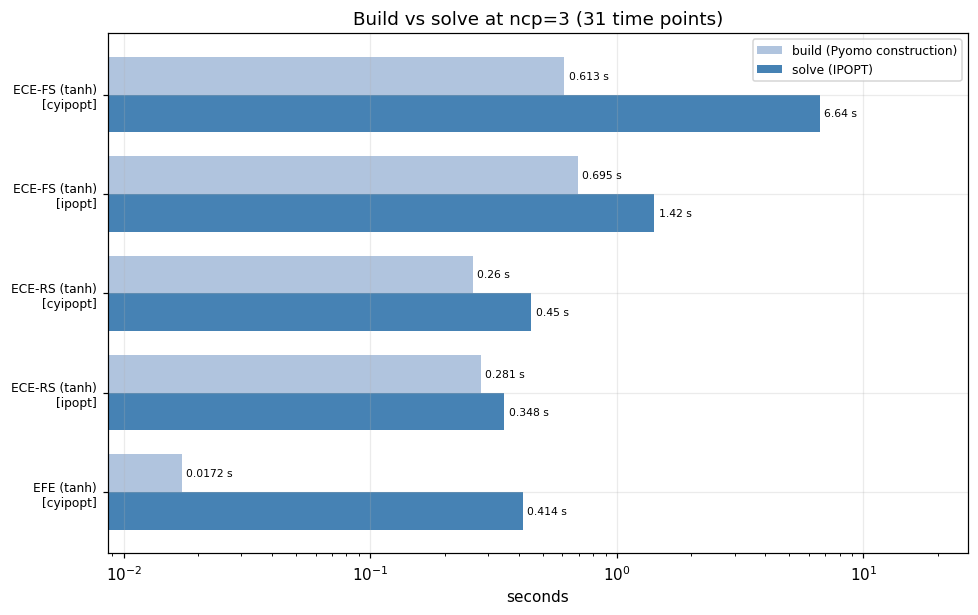

In [172]:
# --- build vs solve, at the largest ncp ---
# Every (method, solver) row, so each ECE method shows both the .nl (ipopt) and
# the in-process (cyipopt) route, and EFE is compared like-for-like with the
# cyipopt rows. Listed alphabetically from the top.
ncp_max = max(NCP_LIST)
bar = (ok[ok["ncp"] == ncp_max]
       .sort_values(["method", "solver"], ascending=False))

# Build and solve side by side, not stacked: on a log axis a stacked segment's
# length does not show its value, and a very short build (EFE) falls off the
# left edge entirely. Note t_solve_s includes Pyomo writing the model out for
# IPOPT, which is larger for the ECE formulations.
fig, ax = plt.subplots(figsize=(9, 0.9 * len(bar) + 1.2))
y = np.arange(len(bar))
h = 0.38
b_build = ax.barh(y + h / 2, bar["t_build_s"], height=h, color=BUILD_COLOR,
                  label="build (Pyomo construction)")
b_solve = ax.barh(y - h / 2, bar["t_solve_s"], height=h, color=SOLVE_COLOR,
                  label="solve (IPOPT)")
for container in (b_build, b_solve):
    ax.bar_label(container, fmt="%.3g s", padding=3, fontsize=7)
t_all = np.concatenate([bar["t_build_s"], bar["t_solve_s"]])
ax.set_xlim(t_all.min() / 2, t_all.max() * 4)   # room for the value labels
ax.set_yticks(y)
ax.set_yticklabels([f"{m}\n[{s}]" for m, s in
                    zip(bar["method"], bar["solver"])], fontsize=8)
ax.set_xlabel("seconds")
ax.set_xscale("log")
ax.set_title(f"Build vs solve at ncp={ncp_max} ({NFE * ncp_max + 1} time points)")
ax.legend()
fig.tight_layout()
fig.savefig("CS1_tutorial_build_vs_solve.png")
plt.show()

TODO: maybe remove the first run vs repeated runs thing. I don't know if it adds anything. 

In [173]:
# --- first run vs repeated runs, next to the build/solve chart above ---
# t_first_s is the first build + solve of each case, one-time costs included.
# setup_s = t_first_s - (t_build_s + t_solve_s): what the first run cost beyond
# a typical repeated run, mostly TensorFlow tracing for EFE. Small values
# (a few hundredths of a second, either sign) are timing noise.
first = ok[["ncp", "method", "solver", "t_build_s", "t_solve_s",
            "t_first_s"]].copy()
first["build+solve_s"] = first["t_build_s"] + first["t_solve_s"]
first["setup_s"] = first["t_first_s"] - first["build+solve_s"]
first = first[["ncp", "method", "solver", "t_build_s", "t_solve_s",
               "build+solve_s", "t_first_s", "setup_s"]]

for ncp in NCP_LIST:
    sub = (first[first["ncp"] == ncp]
           .drop(columns="ncp")
           .sort_values("t_first_s")
           .round(4))
    print(f"\nncp = {ncp}   ({NFE * ncp + 1} time points)")
    print(sub.to_string(index=False))


ncp = 2   (21 time points)
       method  solver  t_build_s  t_solve_s  build+solve_s  t_first_s  setup_s
ECE-RS (tanh) cyipopt     0.0889     0.1777         0.2666     0.2661  -0.0005
ECE-RS (tanh)   ipopt     0.0941     0.1777         0.2718     0.2782   0.0064
   EFE (tanh) cyipopt     0.0083     0.1992         0.2075     0.6679   0.4604
ECE-FS (tanh)   ipopt     0.2227     0.7487         0.9714     1.0049   0.0335
ECE-FS (tanh) cyipopt     0.2333     2.2123         2.4456     2.4033  -0.0423

ncp = 3   (31 time points)
       method  solver  t_build_s  t_solve_s  build+solve_s  t_first_s  setup_s
ECE-RS (tanh) cyipopt     0.2599     0.4495         0.7094     0.7332   0.0238
ECE-RS (tanh)   ipopt     0.2805     0.3485         0.6290     0.7342   0.1052
   EFE (tanh) cyipopt     0.0172     0.4143         0.4315     1.0896   0.6581
ECE-FS (tanh)   ipopt     0.6947     1.4155         2.1102     1.5992  -0.5110
ECE-FS (tanh) cyipopt     0.6128     6.6363         7.2491     7.4835   0.2

## 4.2 &nbsp;Control trajectories

Every formulation is a different encoding of the same mathematics, so
every formulation that is wired up correctly must return the **same control
trajectory**, up to surrogate error, which differs between the `tanh` and `relu`
networks but not between formulations sharing a network.

The dashed black line is the mechanistic solution at the same `ncp`. Where
formulations coincide, each later one is drawn thinner on top of the one before, so
every formulation stays visible as an outline.

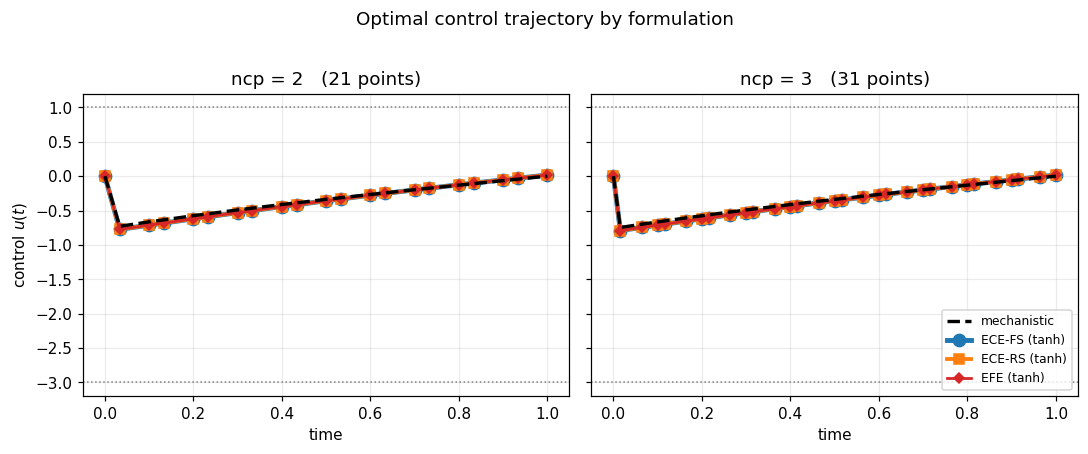

In [174]:
def representative(ncp, formulation, activation):
    """One trajectory per (formulation, activation): backends agree, so we
    only need one. Prefer the .nl backend for determinism."""
    for solver in ("ipopt", "cyipopt"):
        key = (ncp, formulation, activation, solver, "exact")
        if key in TRAJ:
            return TRAJ[key]
    return None


combos = sorted({(r["formulation"], r["activation"]) for r in results
                 if not r["status"].startswith("FAILED")})

fig, axes = plt.subplots(1, len(NCP_LIST), figsize=(5 * len(NCP_LIST), 4),
                         sharey=True)
axes = np.atleast_1d(axes)

for a, ncp in zip(axes, NCP_LIST):
    a.plot(REF_BY_NCP[ncp]["traj"]["t"], REF_BY_NCP[ncp]["traj"]["u"], **REF_KW)
    # Formulations that share a network give identical trajectories, so draw
    # each successive one thinner and smaller on top of the last (layer_kw).
    for k, (fname, act) in enumerate(combos):
        tr = representative(ncp, fname, act)
        if tr is None:
            continue
        meth = method_label(fname, act)
        a.plot(tr["t"], tr["u"], "-", label=meth,
               **method_style(meth), **layer_kw(k))
    a.axhline(U_BOUNDS[0], **BOUND_KW)
    a.axhline(U_BOUNDS[1], **BOUND_KW)
    a.set_xlabel("time")
    a.set_title(f"ncp = {ncp}   ({NFE * ncp + 1} points)")

axes[0].set_ylabel(r"control $u(t)$")
axes[-1].legend(loc="lower right")
fig.suptitle("Optimal control trajectory by formulation", y=1.02)
fig.tight_layout()
fig.savefig("CS1_tutorial_control_trajectories.png")
plt.show()

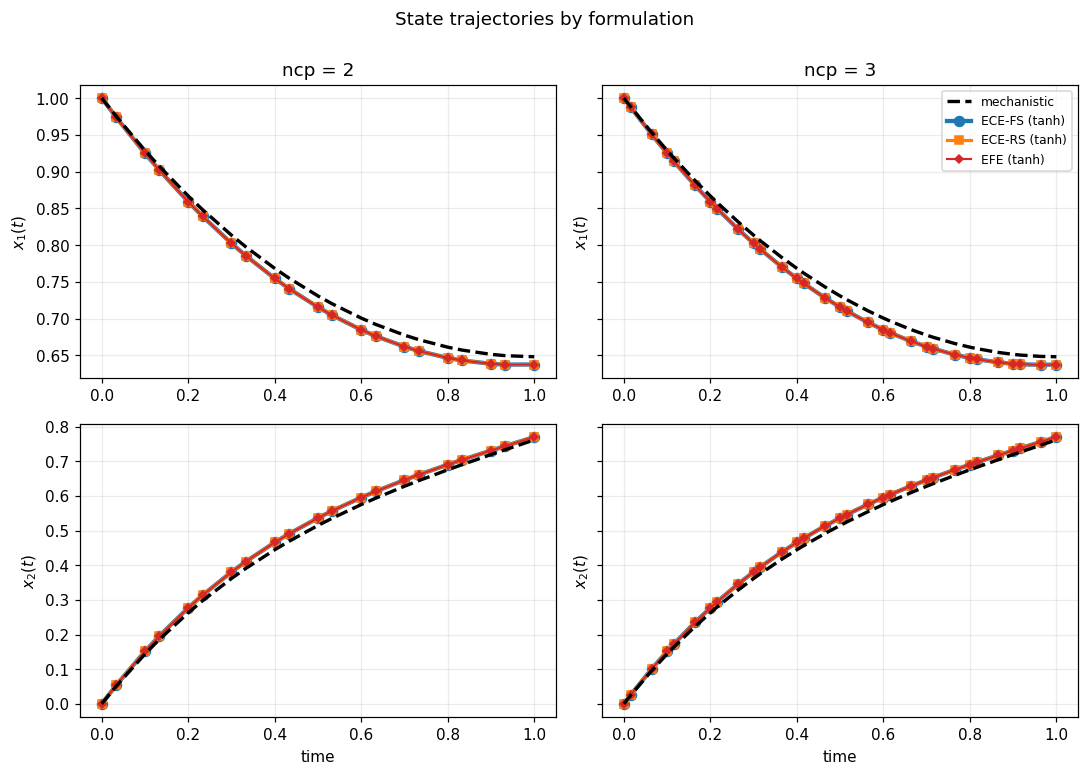

In [175]:
# squeeze=False keeps axes 2-D (2 x n) even for a single ncp; np.atleast_2d
# would turn a (2,) column into a (1, 2) row and break axes[r, col].
fig, axes = plt.subplots(2, len(NCP_LIST), figsize=(5 * len(NCP_LIST), 7),
                         sharey="row", squeeze=False)

for col, ncp in enumerate(NCP_LIST):
    ref = REF_BY_NCP[ncp]["traj"]
    for r, sname in enumerate(("x1", "x2")):
        a = axes[r, col]
        a.plot(ref["t"], ref[sname], **REF_KW)
        for k, (fname, act) in enumerate(combos):
            tr = representative(ncp, fname, act)
            if tr is None:
                continue
            meth = method_label(fname, act)
            a.plot(tr["t"], tr[sname], "-", label=meth,
                   **method_style(meth), **layer_kw(k, lw0=2.8, ms0=6.5))
        a.set_ylabel(f"${sname[0]}_{sname[1]}(t)$")
        if r == 0:
            a.set_title(f"ncp = {ncp}")
        else:
            a.set_xlabel("time")

axes[0, -1].legend()
fig.suptitle("State trajectories by formulation", y=1.0)
fig.tight_layout()
fig.savefig("CS1_tutorial_state_trajectories.png")
plt.show()

## 4.3 &nbsp;Do the formulations agree?


1. **Within one network, do all formulations return the same optimum?**
   They should. A nonzero spread points to a bug inside one formulation (a wrong
   grey-box derivative, a bounds or linking mistake on one path) or to two
   formulations landing in different local optima of this nonconvex problem.
   Either way it is *not* a property of the network.
2. **How far is each network's optimum from the mechanistic one?**
   That gap is surrogate error, and it is the price of using a NODE at all.

In [176]:
# Only converged rows are evidence about the optimum. Including a
# maxIterations row would report a mismatch that is really just a solve
# that stopped early.
trust = ok[ok["trustworthy"]]

print("1) Agreement across formulations sharing the same network")
print("   (nonzero spread => formulation-specific bug or a different local optimum)\n")

agree = []
for (ncp, act), grp in trust.groupby(["ncp", "activation"]):
    n_form = grp["formulation"].nunique()
    spread = grp["objective"].max() - grp["objective"].min()
    if n_form < 2:
        verdict = "only 1 formulation converged - nothing to compare"
    elif spread < 1e-5:
        verdict = "OK"
    else:
        verdict = "MISMATCH - formulation bug or different local optimum"
    agree.append({
        "ncp": ncp, "activation": act,
        "formulations": n_form, "rows": len(grp),
        "objective": grp["objective"].median(),
        "spread": spread, "verdict": verdict,
    })
print(pd.DataFrame(agree).to_string(index=False))

print("\n\n2) Surrogate error: NODE optimum vs mechanistic optimum\n")
err = []
for (ncp, act), grp in trust.groupby(["ncp", "activation"]):
    ref_obj = REF_BY_NCP[ncp]["obj"]
    node_obj = grp["objective"].median()
    err.append({
        "ncp": ncp, "activation": act,
        "mechanistic x2(1)": round(ref_obj, 6),
        "NODE x2(1)": round(node_obj, 6),
        "abs error": round(abs(node_obj - ref_obj), 6),
        "rel error %": round(100 * abs(node_obj - ref_obj) / abs(ref_obj), 3),
    })
print(pd.DataFrame(err).to_string(index=False))

not_conv = ok[ok["status"] != "optimal"]
if len(not_conv):
    print(f"\n   ({len(not_conv)} run(s) did not converge and are excluded "
          f"above:")
    for _, r in not_conv.iterrows():
        print(f"      ncp={r['ncp']} {r['method']} [{r['solver']}, "
              f"{r['hessian']}] -> {r['status']} after {r['iters']} iters")
    print("   )")

1) Agreement across formulations sharing the same network
   (nonzero spread => formulation-specific bug or a different local optimum)

 ncp activation  formulations  rows  objective       spread verdict
   2       tanh             3     5   0.769970 5.000000e-08      OK
   3       tanh             3     5   0.769972 5.000000e-08      OK


2) Surrogate error: NODE optimum vs mechanistic optimum

 ncp activation  mechanistic x2(1)  NODE x2(1)  abs error  rel error %
   2       tanh           0.761586    0.769970   0.008384        1.101
   3       tanh           0.761594    0.769972   0.008378        1.100


In [177]:
RESULTS.to_csv(RESULTS_CSV, index=False)
print(f"wrote {RESULTS_CSV}  ({len(RESULTS)} rows)")
for f in ("CS1_tutorial_scaling.png", "CS1_tutorial_build_vs_solve.png",
          "CS1_tutorial_control_trajectories.png",
          "CS1_tutorial_state_trajectories.png"):
    print(f"wrote {f}")

wrote CS1_formulation_comparison.csv  (10 rows)
wrote CS1_tutorial_scaling.png
wrote CS1_tutorial_build_vs_solve.png
wrote CS1_tutorial_control_trajectories.png
wrote CS1_tutorial_state_trajectories.png
